In [1]:
print(df_clean.shape)
df_clean.head()

NameError: name 'df_clean' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [3]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Remove duplicate rows
df_clean = df.drop_duplicates().copy()

# Convert InvoiceDate into datetime format
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Remove rows with invalid quantity or price
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Calculate total sales
df_clean["TotalSales"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Cleaned dataset shape:", df_clean.shape)
df_clean.head()

Cleaned dataset shape: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [5]:
# Group sales by product
product_sales = df_clean.groupby("StockCode").agg(
    ProductDescription=("Description", "first"),
    TotalQuantity=("Quantity", "sum"),
    TotalSales=("TotalSales", "sum")
).reset_index()

# Sort products by total sales
top_10_products = product_sales.sort_values(
    by="TotalSales",
    ascending=False
).head(10)

# Display top 10 products
top_10_products

,StockCode,ProductDescription,TotalQuantity,TotalSales
3911,DOT,DOTCOM POSTAGE,706,206248.77
1235,22423,REGENCY CAKESTAND 3 TIER,13851,174156.54
2390,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
3539,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75
2468,47566,PARTY BUNTING,18283,99445.23
3528,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
1945,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
3914,POST,POSTAGE,3150,78101.88
3912,M,Manual,6984,77750.27
1867,23084,RABBIT NIGHT LIGHT,30739,66870.03


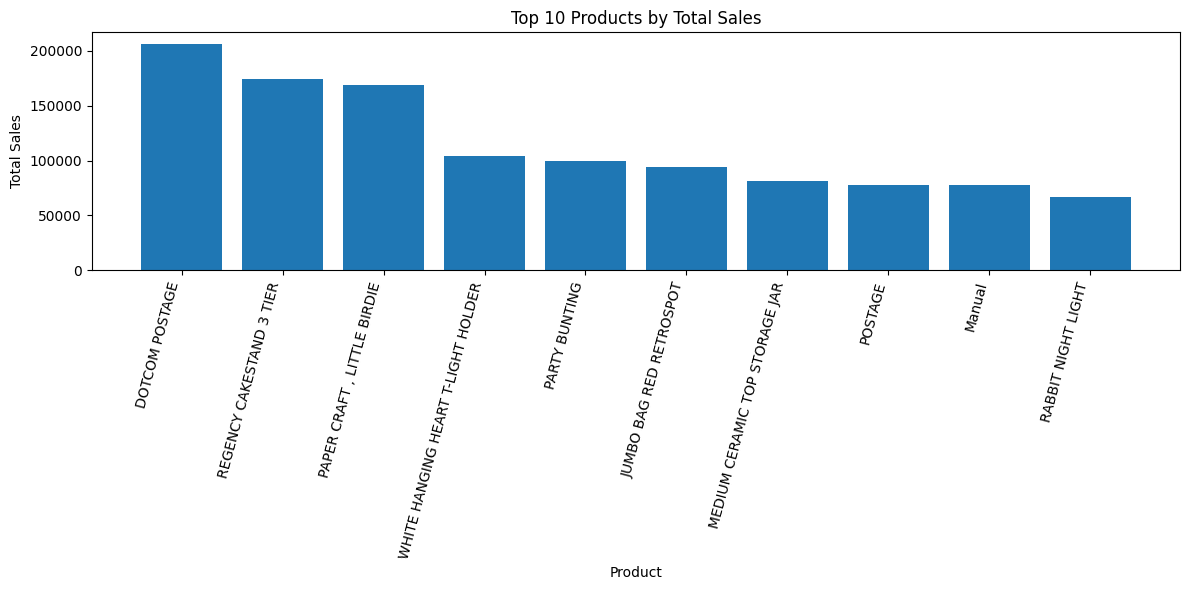

In [6]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_products["ProductDescription"].astype(str),
    top_10_products["TotalSales"]
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

In [7]:
# Save product analysis results as CSV
top_10_products.to_csv(
    "Day23_Top_10_Products.csv",
    index=False
)

# Download CSV file
from google.colab import files
files.download("Day23_Top_10_Products.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>